# 14 潜熱モデル比較

同一の32℃外気条件でrh95・bf・coil_aoafを比較する。

## 到達目標
同じ入力でも潜熱量が異なる。Af／Aoの面積[m²]、bf、機器能力を記録する。収束と物理的な目標達成を分けて確認する。

## 実行環境
Python 3.10以上とvtsimnx engineが必要です。Colabのlocalhostは手元PCのサーバーを指しません。次の設定セルのAPI URLを到達可能なものに変更します。APIキーは環境変数で渡し、ノートに保存しません。

検証engine commit: `5eeffb2f8012a2fe41bca705450b0dd0a952326d`。入力モデルは実計算確認済ですが、原住宅の年間再現とは範囲が異なります。

## 実行版の使い方
このノートは検証対象のvtsimnx commit 5eeffb2f8012a2fe41bca705450b0dd0a952326d に合わせた代表教材です。上から順に実行します。
Pythonクライアントの導入だけではengineは起動しません。教材17以外は接続可能なengineと、必要に応じてVTSIMNX_API_KEYが必要です。Colabの127.0.0.1は手元PCのengineを指しません。
入力はノート内に含めています。元のDriveパスや測定CSVを別途読む必要はありません。
出力は教材フォルダ内のresults/14/に保存します。詳しい準備は同じフォルダの00_実行ガイド.ipynbを参照してください。


In [1]:
import os, sys, subprocess
# 検証runnerのみ専用環境で導入済みの依存を再利用する。通常はこのセルで導入する。
if os.environ.get("VTSIMNX_TUTORIAL_SKIP_INSTALL") != "1":
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", "pip", "setuptools>=68,<81", "wheel"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
        "vtsimnx @ git+https://github.com/iguchi-lab/vtsimnx@5eeffb2f8012a2fe41bca705450b0dd0a952326d",
        "matplotlib", "japanize-matplotlib"])


In [2]:
import os, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib
from IPython.display import display
import vtsimnx as vt

# ローカルJupyterでは、ノートブックと同じフォルダを作業フォルダにする。
DATA_DIR = Path(os.environ.get("VTSIMNX_TUTORIAL_DATA", ".")).expanduser().resolve()
BASE_URL = os.environ.get("VTSIMNX_API_URL", "http://127.0.0.1:8000")
API_KEY = os.environ.get("VTSIMNX_API_KEY")
OUTPUT = DATA_DIR / "results" / "14"
OUTPUT.mkdir(parents=True, exist_ok=True)


## 入力を読む
次の辞書はvtsimnxのネイティブ形式です。風量はm³/s、熱量はW、熱容量はJ/Kです。

In [3]:
configs = {'14_rh95': {'builder': {},
             'simulation': {'index': {'start': '2026-01-01T00:00:00',
                                      'end': '2026-01-01T05:00:00',
                                      'length': 6,
                                      'timestep': 3600},
                            'coupling': {'moisture_enabled': True},
                            'tolerance': {'thermal': 0.001,
                                          'convergence': 1e-06,
                                          'coupling_humidity': 1e-08}},
             'nodes': [{'key': 'outside', 't': 32, 'x': 0.018},
                       {'key': 'room', 't': 26, 'x': 0.018, 'v': 40, 'calc_t': True, 'calc_x': True}],
             'ventilation_branches': [{'key': 'outside->room',
                                       'source': 'outside',
                                       'target': 'room',
                                       'vol': 0.05},
                                      {'key': 'room->outside',
                                       'source': 'room',
                                       'target': 'outside',
                                       'vol': 0.05}],
             'thermal_branches': [{'key': 'outside->room',
                                   'source': 'outside',
                                   'target': 'room',
                                   'conductance': 1000}],
             'aircon': [{'key': 'AC',
                         'set': 'room',
                         'outside': 'outside',
                         'pre_temp': 26,
                         'pre_rh': 60,
                         'mode': 'COOLING',
                         'model': 'RAC',
                         'vol': 0.1,
                         'control_mode': 'temperature_priority',
                         'max_overcooling': 2,
                         'ac_spec': {'latent_method': 'rh95',
                                     'bf': 0.2,
                                     'Af': 0.133,
                                     'Ao': 4.84,
                                     'Q': {'cooling': {'min': 0.01, 'mid': 3.8, 'rtd': 7.6, 'max': 20},
                                           'heating': {'min': 2.7, 'mid': 3.9, 'rtd': 7.7}},
                                     'P': {'cooling': {'rtd': 2.4}, 'heating': {'rtd': 2.1}}}}]},
 '14_bf': {'builder': {},
           'simulation': {'index': {'start': '2026-01-01T00:00:00',
                                    'end': '2026-01-01T05:00:00',
                                    'length': 6,
                                    'timestep': 3600},
                          'coupling': {'moisture_enabled': True},
                          'tolerance': {'thermal': 0.001, 'convergence': 1e-06, 'coupling_humidity': 1e-08}},
           'nodes': [{'key': 'outside', 't': 32, 'x': 0.018},
                     {'key': 'room', 't': 26, 'x': 0.018, 'v': 40, 'calc_t': True, 'calc_x': True}],
           'ventilation_branches': [{'key': 'outside->room',
                                     'source': 'outside',
                                     'target': 'room',
                                     'vol': 0.05},
                                    {'key': 'room->outside',
                                     'source': 'room',
                                     'target': 'outside',
                                     'vol': 0.05}],
           'thermal_branches': [{'key': 'outside->room',
                                 'source': 'outside',
                                 'target': 'room',
                                 'conductance': 1000}],
           'aircon': [{'key': 'AC',
                       'set': 'room',
                       'outside': 'outside',
                       'pre_temp': 26,
                       'pre_rh': 60,
                       'mode': 'COOLING',
                       'model': 'RAC',
                       'vol': 0.1,
                       'control_mode': 'temperature_priority',
                       'max_overcooling': 2,
                       'ac_spec': {'latent_method': 'bf',
                                   'bf': 0.2,
                                   'Af': 0.133,
                                   'Ao': 4.84,
                                   'Q': {'cooling': {'min': 0.01, 'mid': 3.8, 'rtd': 7.6, 'max': 20},
                                         'heating': {'min': 2.7, 'mid': 3.9, 'rtd': 7.7}},
                                   'P': {'cooling': {'rtd': 2.4}, 'heating': {'rtd': 2.1}}}}]},
 '14_coil_aoaf': {'builder': {},
                  'simulation': {'index': {'start': '2026-01-01T00:00:00',
                                           'end': '2026-01-01T05:00:00',
                                           'length': 6,
                                           'timestep': 3600},
                                 'coupling': {'moisture_enabled': True},
                                 'tolerance': {'thermal': 0.001,
                                               'convergence': 1e-06,
                                               'coupling_humidity': 1e-08}},
                  'nodes': [{'key': 'outside', 't': 32, 'x': 0.018},
                            {'key': 'room', 't': 26, 'x': 0.018, 'v': 40, 'calc_t': True, 'calc_x': True}],
                  'ventilation_branches': [{'key': 'outside->room',
                                            'source': 'outside',
                                            'target': 'room',
                                            'vol': 0.05},
                                           {'key': 'room->outside',
                                            'source': 'room',
                                            'target': 'outside',
                                            'vol': 0.05}],
                  'thermal_branches': [{'key': 'outside->room',
                                        'source': 'outside',
                                        'target': 'room',
                                        'conductance': 1000}],
                  'aircon': [{'key': 'AC',
                              'set': 'room',
                              'outside': 'outside',
                              'pre_temp': 26,
                              'pre_rh': 60,
                              'mode': 'COOLING',
                              'model': 'RAC',
                              'vol': 0.1,
                              'control_mode': 'temperature_priority',
                              'max_overcooling': 2,
                              'ac_spec': {'latent_method': 'coil_aoaf',
                                          'bf': 0.2,
                                          'Af': 0.133,
                                          'Ao': 4.84,
                                          'Q': {'cooling': {'min': 0.01, 'mid': 3.8, 'rtd': 7.6, 'max': 20},
                                                'heating': {'min': 2.7, 'mid': 3.9, 'rtd': 7.7}},
                                          'P': {'cooling': {'rtd': 2.4}, 'heating': {'rtd': 2.1}}}}]}}


## 実行と結果の取得
計算ごとの要求JSONを保存し、必要な系列をDataFrameとして取得します。

In [4]:
results = {}
for name, config in configs.items():
    results[name] = vt.run_calc(BASE_URL, config, api_key=API_KEY,
        as_result=True, raise_on_error=True, timeout=1800, request_output_path=OUTPUT / (name + "_request.json"))
    print(name, results[name].artifact_dir)


14_rh95 artifacts.1794699428903.output.d13834b421f8422f815c9fea549ab392


14_bf artifacts.1794699429922.output.08387bc3715d4a58b4123e0b5a435da1


14_coil_aoaf artifacts.1794699430940.output.9f34c9f309734c62bf5a50001893f8af


14_rh95


,AC
time,
2026-01-01 00:00:00,2053.640381
2026-01-01 01:00:00,1821.881592
2026-01-01 02:00:00,1805.898193
2026-01-01 03:00:00,1804.795898
2026-01-01 04:00:00,1804.719849


14_bf


,AC
time,
2026-01-01 00:00:00,2051.161377
2026-01-01 01:00:00,1819.682373
2026-01-01 02:00:00,1803.718262
2026-01-01 03:00:00,1802.617310
2026-01-01 04:00:00,1802.541382


14_coil_aoaf


,AC
time,
2026-01-01 00:00:00,2085.171631
2026-01-01 01:00:00,1843.895142
2026-01-01 02:00:00,1827.944946
2026-01-01 03:00:00,1826.890503
2026-01-01 04:00:00,1826.819458


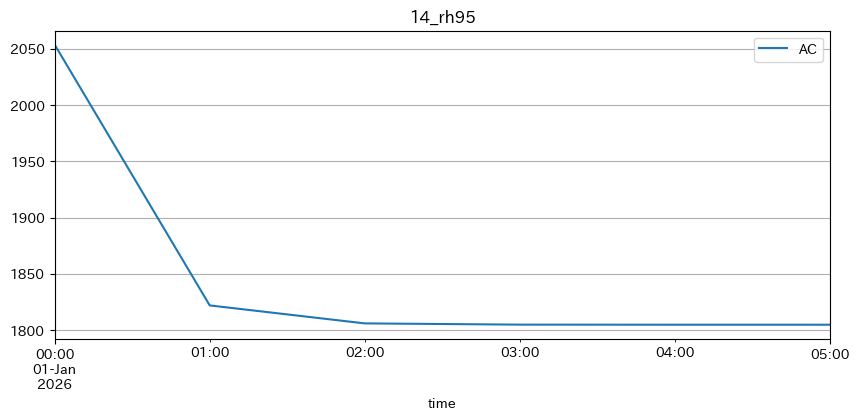

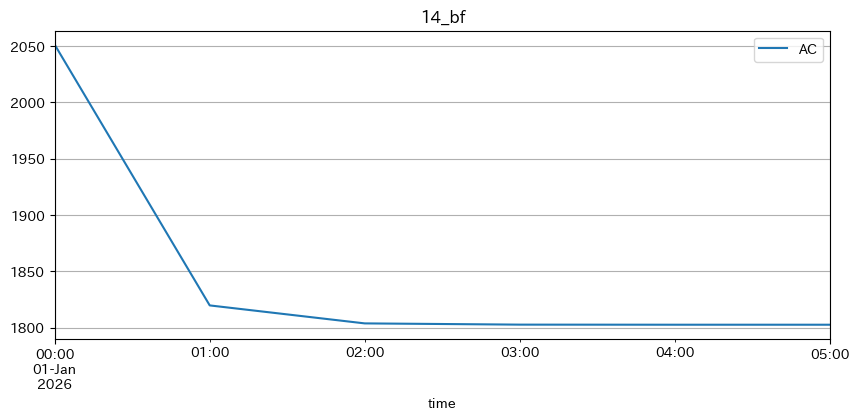

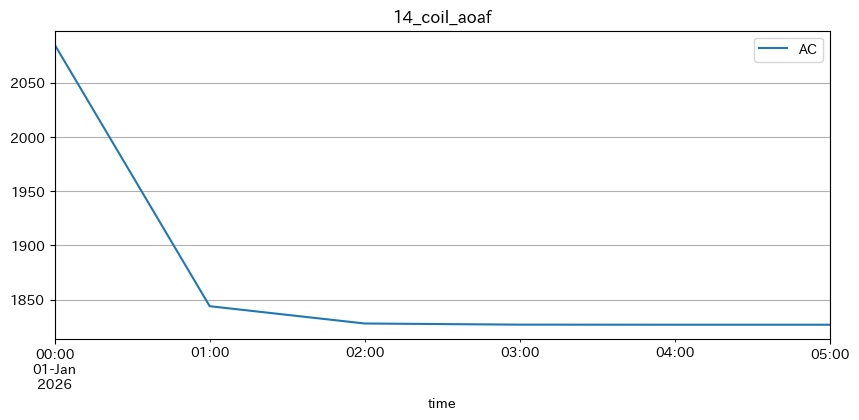

In [5]:
frames = {name: result.get_series_df('aircon_latent_heat', raise_on_error=True) for name, result in results.items()}
for name, frame in frames.items():
    print(name)
    display(frame.head())
    frame.to_csv(OUTPUT / (name + "_aircon_latent_heat.csv"), encoding="utf-8-sig")
    frame.plot(title=name, figsize=(10, 4), grid=True)


## 確認・発展
湿度を低い値から増やし、乾き／濡れの遷移を見る。

保存された時刻の値は当該ステップ更新後の値です。初期値との比較ではこの差に注意します。

## 原典との対応
- S001 250929_再熱考慮_電中研モデル.ipynb
- S036 電中研モデル_250210.ipynb のコピー
- S037 電中研モデル_再熱考慮_旧エアコン250727.ipynb
- S182 240310_集合住宅向け床吹出型全館空調_モデル化_K_1.ipynb
- S183 240310_集合住宅向け床吹出型全館空調_モデル化_K_2.ipynb
- S184 240310_集合住宅向け床吹出型全館空調_モデル化_K_3.ipynb
- S185 240310_集合住宅向け床吹出型全館空調_モデル化_K_4.ipynb
- S186 240310_集合住宅向け床吹出型全館空調_モデル化_K_5.ipynb
- S187 240310_集合住宅向け床吹出型全館空調_モデル化_M-1.ipynb
- S188 240310_集合住宅向け床吹出型全館空調_モデル化_M-2.ipynb
- S189 240310_集合住宅向け床吹出型全館空調_モデル化_SC.ipynb
- S261 Duct_Central_ACモデル.ipynb のコピー

S番号は原典調査時の識別子です。原典の完全な台帳は管理者のDrive整理資料に保管しています。